In [81]:
import json
import glob
import os
import shutil

import numpy as np
import matplotlib.pyplot as plt
import cv2

In [2]:
labels_folder = "../../deep-learning-training/data_preprocessing/annotated_from_Maor/"

In [7]:
json_paths = sorted(glob.glob(os.path.join(labels_folder, "*.json")))

In [58]:
img_paths = []

bboxes = {}

for i in json_paths:
    with open(i, 'rt') as f:
        data = json.load(f)
    for j in data:
        img_paths.append(j['assetMetadata']['name'])
        bboxes[img_paths[-1]] = j['resultData']['boxes']['entities']

In [59]:
len(img_paths), len(set(img_paths))

(1004, 1003)

In [60]:
img_paths = set(img_paths)

In [61]:
imgs_done = set([os.path.basename(i) for i in glob.glob("../../../db/2Annotate_Objects/done/*.bmp")])
imgs_all = set([os.path.basename(i) for i in glob.glob("../../../db/2Annotate_Objects/*.bmp")])

In [62]:
len(imgs_all), len(imgs_done)

(1456, 514)

In [63]:
imgs_all.intersection(imgs_done)

set()

In [64]:
len(img_paths.intersection(imgs_all))

498

In [65]:
len(img_paths.intersection(imgs_done))

503

In [66]:
imgs_done.difference(imgs_done).difference(imgs_all)

set()

In [50]:
for i in img_paths.intersection(imgs_all):
    shutil.copy(os.path.join("../../../db/2Annotate_Objects", i), os.path.join("imgs", i))

for i in img_paths.intersection(imgs_done):
    shutil.copy(os.path.join("../../../db/2Annotate_Objects/done", i), os.path.join("imgs", i))

In [67]:
len(glob.glob("imgs/*.bmp"))

1001

In [68]:
len(data)

50

In [83]:
box = np.array([[i['x'], i['y']]  for i in bboxes[list(img_paths)[0]][0]['coordinates']])
box

array([[434, 261],
       [434, 175],
       [512, 175],
       [512, 261]])

In [85]:
box.min(axis=0)

array([434, 175])

In [75]:
img = cv2.imread(os.path.join('imgs', list(img_paths)[0]))

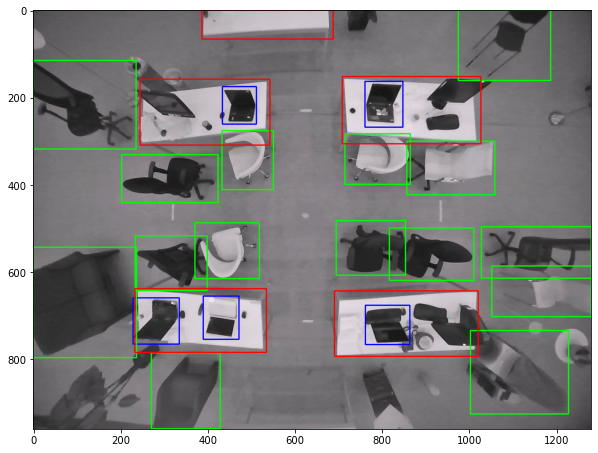

In [94]:
COLORS = {
    "Table": (255, 0, 0),
    "Chair": (0, 255, 0),
    "Laptop": (0, 0, 255)
}

tmp = img.copy()
for bbox in bboxes[list(img_paths)[0]]:
    box = np.array([[i['x'], i['y']]  for i in bbox['coordinates']])
    tmp = cv2.rectangle(tmp, box.min(axis=0), box.max(axis=0), COLORS[bbox['entityTypeName']], 2)

plt.figure(figsize=(10, 10))
plt.imshow(tmp)

In [102]:
processed_bboxes = {}
for img_name in glob.glob("imgs/*.bmp"):
    img_name = os.path.basename(img_name)
    
    tmp_bboxes = []
    for bbox in bboxes[img_name]:
        box = np.array([[i['x'], i['y']]  for i in bbox['coordinates']])
        tmp_bboxes.append({"class": bbox['entityTypeName'], "lt": box.min(axis=0).tolist(), "rb": box.max(axis=0).tolist()})
    processed_bboxes[img_name] = tmp_bboxes

In [103]:
len(processed_bboxes)

1001

In [105]:
img_name, processed_bboxes[img_name]

('PG1_DL_H300_Office_DESK_lineShirt_26_14_55_47_2017.avi_snapshot_00.00.600.bmp',
 [{'class': 'Table', 'lt': [234, 44], 'rb': [403, 311]},
  {'class': 'Table', 'lt': [547, 0], 'rb': [756, 254]},
  {'class': 'Table', 'lt': [983, 20], 'rb': [1071, 213]},
  {'class': 'Table', 'lt': [1037, 333], 'rb': [1122, 526]},
  {'class': 'Table', 'lt': [822, 312], 'rb': [950, 539]},
  {'class': 'Table', 'lt': [493, 355], 'rb': [731, 588]},
  {'class': 'Table', 'lt': [280, 385], 'rb': [371, 599]},
  {'class': 'Table', 'lt': [87, 634], 'rb': [181, 815]},
  {'class': 'Table', 'lt': [314, 718], 'rb': [483, 954]},
  {'class': 'Table', 'lt': [500, 673], 'rb': [688, 905]},
  {'class': 'Table', 'lt': [832, 643], 'rb': [974, 876]},
  {'class': 'Chair', 'lt': [389, 185], 'rb': [501, 291]},
  {'class': 'Laptop', 'lt': [294, 188], 'rb': [391, 253]},
  {'class': 'Laptop', 'lt': [694, 147], 'rb': [747, 216]},
  {'class': 'Chair', 'lt': [737, 61], 'rb': [836, 239]},
  {'class': 'Chair', 'lt': [1064, 48], 'rb': [117

In [106]:
with open("annotation.json", 'wt') as f:
    json.dump(processed_bboxes, f)

In [117]:
img_names = [i.replace('.bmp', '') for i in list(processed_bboxes.keys())]

In [143]:
path = '../../deep-learning-training/dataset_list/Finetune_set_1238_list/'

with open(os.path.join(path, "train_image.txt"), 'rt') as f:
    lines = f.readlines()
train_lines = [os.path.basename(i).replace(".jpg\n", "").replace(".bmp\n", "") for i in lines]

with open(os.path.join(path, "val_image.txt"), 'rt') as f:
    lines = f.readlines()
val_lines = [os.path.basename(i).replace(".jpg\n", "").replace(".bmp\n", "") for i in lines]

In [144]:
len(train_lines), len(set(img_names).intersection(train_lines))

(1238, 498)

In [145]:
len(val_lines), len(set(img_names).intersection(val_lines))

(106, 60)

In [146]:
# Finetune_set_550_list - OK
# Finetune_set_1238_list - not OK

In [147]:
set(val_lines).difference(img_names)

{'H240_cam2_desks_1ppl_10fps_2.avi_snapshot_00.01.365',
 'PG1_DL_H280_Office_desk_back_8U_NY_28_15_19_21_2016.avi_snapshot_00.00.032',
 'PG1_DL_H300_Office_DESK_12_16_31_28_2017.avi_snapshot_00.00.299',
 'PG1_DL_H300_office_Beige_Carpet2_18_12_34_08_2016.avi_snapshot_02.56.854',
 'PG1_DL_H300_office_blackC_Table_06_09_28_15_2016.avi_snapshot_02.14.625',
 'PG1_DL_H300_office_black_uTable_27_10_42_37_2016.avi_snapshot_01.37.513',
 'PG1_H271_office_HotDesk_WeWork_09_15_25_59_2016.avi_snapshot_00.00.939',
 'PG1_H300_HD_Occlusion_NY_stnd_171106_1509283857.avi_snapshot_04.37.888',
 'PG1_H300_MR_M_GlassWall_NY_1509274719.avi_snapshot_04.14.191',
 'PG1_H300_nR1_office_MR_NY_U08_1495117937.avi_snapshot_14.22.484',
 'PG1_H350_Batzra_walk_stand_13_10_29_09_2016.avi_snapshot_05.01.751'}

In [151]:
tmp_names = set([os.path.basename(i).replace(".bmp", "") for i in imgs_all])
len(tmp_names)

1456

In [155]:
len(train_lines), len(set(tmp_names).intersection(train_lines))

(1238, 1230)

In [156]:
len(val_lines), len(set(tmp_names).intersection(val_lines))

(106, 17)

In [157]:
set(val_lines).difference(tmp_names)

{'H240_cam2_OpenSpace_10fps_2.avi_snapshot_02.50.296',
 'H317_Cam2_hotdesk_20fps_black_20211130_160407.avi_snapshot_00.00.926',
 'H317_Cam2_ladders_20fps_black_20211130_144005.avi_snapshot_00.00.872',
 'H317_Cam2_meeting_room_20fps_black_20211130_152430.avi_snapshot_00.01.707',
 'H317_Cam2_meeting_room_20fps_dev3_20211130_145425.avi_snapshot_00.01.043',
 'H400_MP_4M_Stand_Mon_Feb_02_11_27_56_2015.avi_snapshot_00.01.188',
 'PG1_CIR_H270_office_HotDesk_13_10_12_41_2016.avi_snapshot_11.45.194',
 'PG1_CIR_H270_office_HotDesk_19_10_52_04_2016.avi_snapshot_11.56.709',
 'PG1_CIR_H270_office_HotDesk_19_10_52_04_OS_2016.avi_snapshot_11.58.021',
 'PG1_CIR_H270_office_HotDesk_19_11_21_19_2016.avi_snapshot_12.13.615',
 'PG1_CIR_H270_office_HotDesk_19_12_16_47_2016.avi_snapshot_00.00.611',
 'PG1_CIR_H300_office_HotDesk_02_14_40_27_2016.avi_snapshot_11.52.876',
 'PG1_CIR_H300_office_HotDesk_09_11_30_19_2016.avi_snapshot_12.01.622',
 'PG1_CIR_H300_office_HotDesk_09_11_30_19_OS_2016.avi_snapshot_00.00

In [159]:
set(tmp_names).intersection(train_lines).difference(img_names)

{'00Deg_50Lux_000cm_ZivFa.avi_snapshot_00.31.722',
 '1P_Lux020_Sun_Jan_25_15_33_07_2015.avi_snapshot_00.00.956',
 '1P_Lux080_Sun_Jan_25_14_57_44_2015.avi_snapshot_00.00.825',
 '2.12.21_H265_objects_1.avi_snapshot_00.00.000',
 '2P_Lux080_Sun_Jan_25_15_10_27_2015.avi_snapshot_00.01.719',
 '2P_Lux100_Sun_Jan_25_14_25_09_2015.avi_snapshot_00.01.253',
 '3P_Lux020_Sun_Jan_25_15_53_39_2015.avi_snapshot_00.01.627',
 '3P_Lux050_Sun_Jan_25_16_07_37_2015.avi_snapshot_00.01.369',
 '3P_Lux080_Sun_Jan_25_15_20_59_2015.avi_snapshot_00.01.400',
 '3P_Lux100_Sun_Jan_25_14_40_35_2015.avi_snapshot_00.01.614',
 '3P_Thu_Jan_29_17_09_56_2015.avi_snapshot_00.01.496',
 'A00_D072_ZivBr_Sun_Nov_23_17_01_25_2014.avi_snapshot_00.02.361',
 'A11_D105_Yael_Tue_Dec_30_15_36_21_2014.avi_snapshot_00.03.633',
 'A12_D098_Yael_Sun_Nov_23_13_35_36_2014.avi_snapshot_00.01.140',
 'A14_D081_Moshe_Sun_Nov_23_15_21_44_2014.avi_snapshot_00.01.013',
 'A26_D090_Amit_Sun_Nov_23_10_42_17_2014.avi_snapshot_00.01.055',
 'A32_D152_Ora_W